# Historical AQI data analysis


In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from vayuayan import CPCBHistorical, set_theme
from vayuayan.plot_theme import INK_2, PALETTE

set_theme()
plt.rcParams["figure.figsize"] = (12, 6)

## 1. Download historical data


In [2]:
client = CPCBHistorical()

city = "Delhi"
year = "2024"
output_file = f"{city.lower()}_aqi_{year}.csv"

df = client.download_past_year_aqi_data_city_level(city, year, output_file)
print(f"Data downloaded to {output_file}")

print(df.head())

Data downloaded to delhi_aqi_2024.csv
  Day  January  February  March  April    May   June   July  August  \
0   1    346.0     176.0  208.0  133.0  200.0  245.0  105.0    64.0   
1   2    340.0     215.0  117.0  144.0  197.0  173.0  118.0    76.0   
2   3    341.0     199.0  126.0  167.0  264.0  155.0  108.0    68.0   
3   4    377.0     274.0  141.0  173.0  282.0  211.0   61.0    64.0   
4   5    333.0     177.0  125.0  174.0  292.0  251.0   77.0    59.0   

   September  October  November  December  
0      101.0    149.0     339.0     285.0  
1       87.0    173.0     318.0     280.0  
2       89.0    162.0     381.0     268.0  
3       69.0    184.0     380.0     178.0  
4       83.0    145.0     372.0     165.0  


## 2. Load and examine the data


In [3]:
df = pd.read_csv(output_file)

print("Dataset Information:")
print(f"Shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nData types:\n{df.dtypes}")
print("\nFirst few rows:")
print(df.sample())

Dataset Information:
Shape: (31, 13)

Columns: ['Day', 'January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']

Data types:
Day            int64
January      float64
February     float64
March        float64
April        float64
May          float64
June         float64
July         float64
August       float64
September    float64
October      float64
November     float64
December     float64
dtype: object

First few rows:
    Day  January  February  March  April    May   June  July  August  \
22   23    368.0     143.0  232.0  190.0  156.0  145.0  93.0    77.0   

    September  October  November  December  
22      165.0    364.0     412.0     406.0  


## 3. Make a statistical summary


In [4]:
print("AQI Statistics:")
print(df.describe())

AQI Statistics:
             Day     January    February       March       April         May  \
count  31.000000   31.000000   29.000000   31.000000   30.000000   31.000000   
mean   16.000000  354.838710  217.586207  175.903226  183.400000  224.032258   
std     9.092121   32.498304   63.680855   33.640605   30.723012   37.689507   
min     1.000000  273.000000  140.000000  117.000000  129.000000  156.000000   
25%     8.500000  336.500000  161.000000  151.000000  165.500000  192.500000   
50%    16.000000  348.000000  199.000000  178.000000  182.500000  230.000000   
75%    23.500000  368.000000  270.000000  196.000000  202.250000  244.500000   
max    31.000000  447.000000  341.000000  243.000000  240.000000  303.000000   

             June        July      August   September     October    November  \
count   30.000000   31.000000   31.000000   30.000000   31.000000   30.000000   
mean   179.133333   96.064516   72.161290  105.100000  234.000000  374.233333   
std     51.481321   

## 4. Show the daily AQI


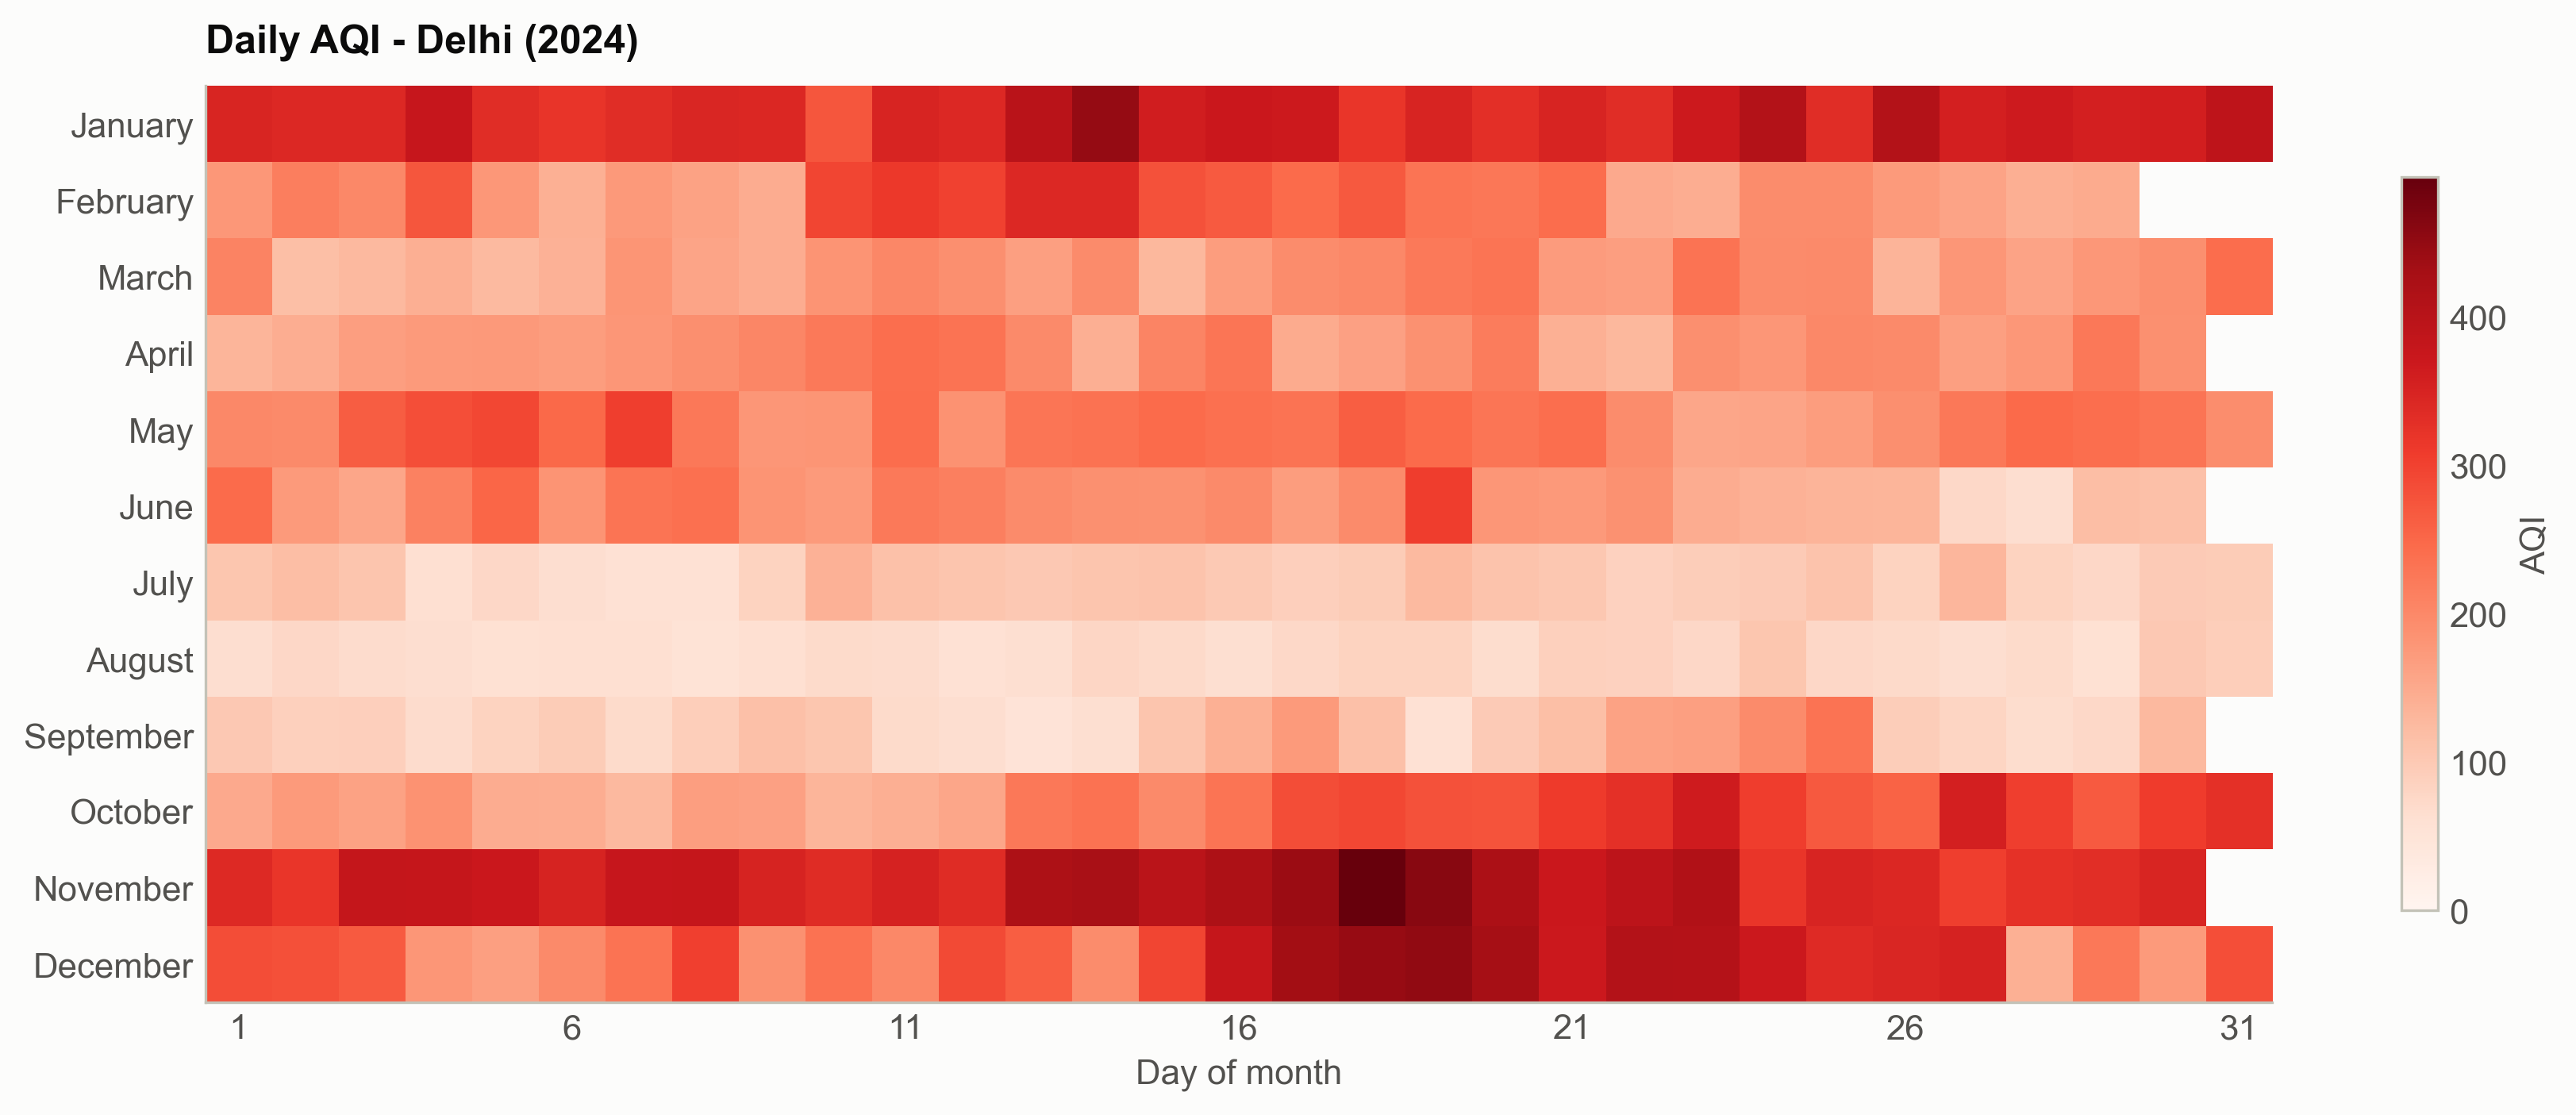

In [5]:
# Blank cells in the month-by-day grid are days without data

months = df.columns[1:]  # Do not include the 'Day' column

fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(
    df[months].T.values, aspect="auto", cmap="Reds", vmin=0, interpolation="nearest"
)
ax.grid(False)
ax.set_yticks(range(len(months)), months)
ax.set_xticks(range(0, len(df), 5), df["Day"].iloc[::5])
ax.set_xlabel("Day of month")
ax.set_title(f"Daily AQI - {city} ({year})")
fig.colorbar(im, ax=ax, shrink=0.8, label="AQI")
plt.show()

## 5. Analyze the monthly AQI


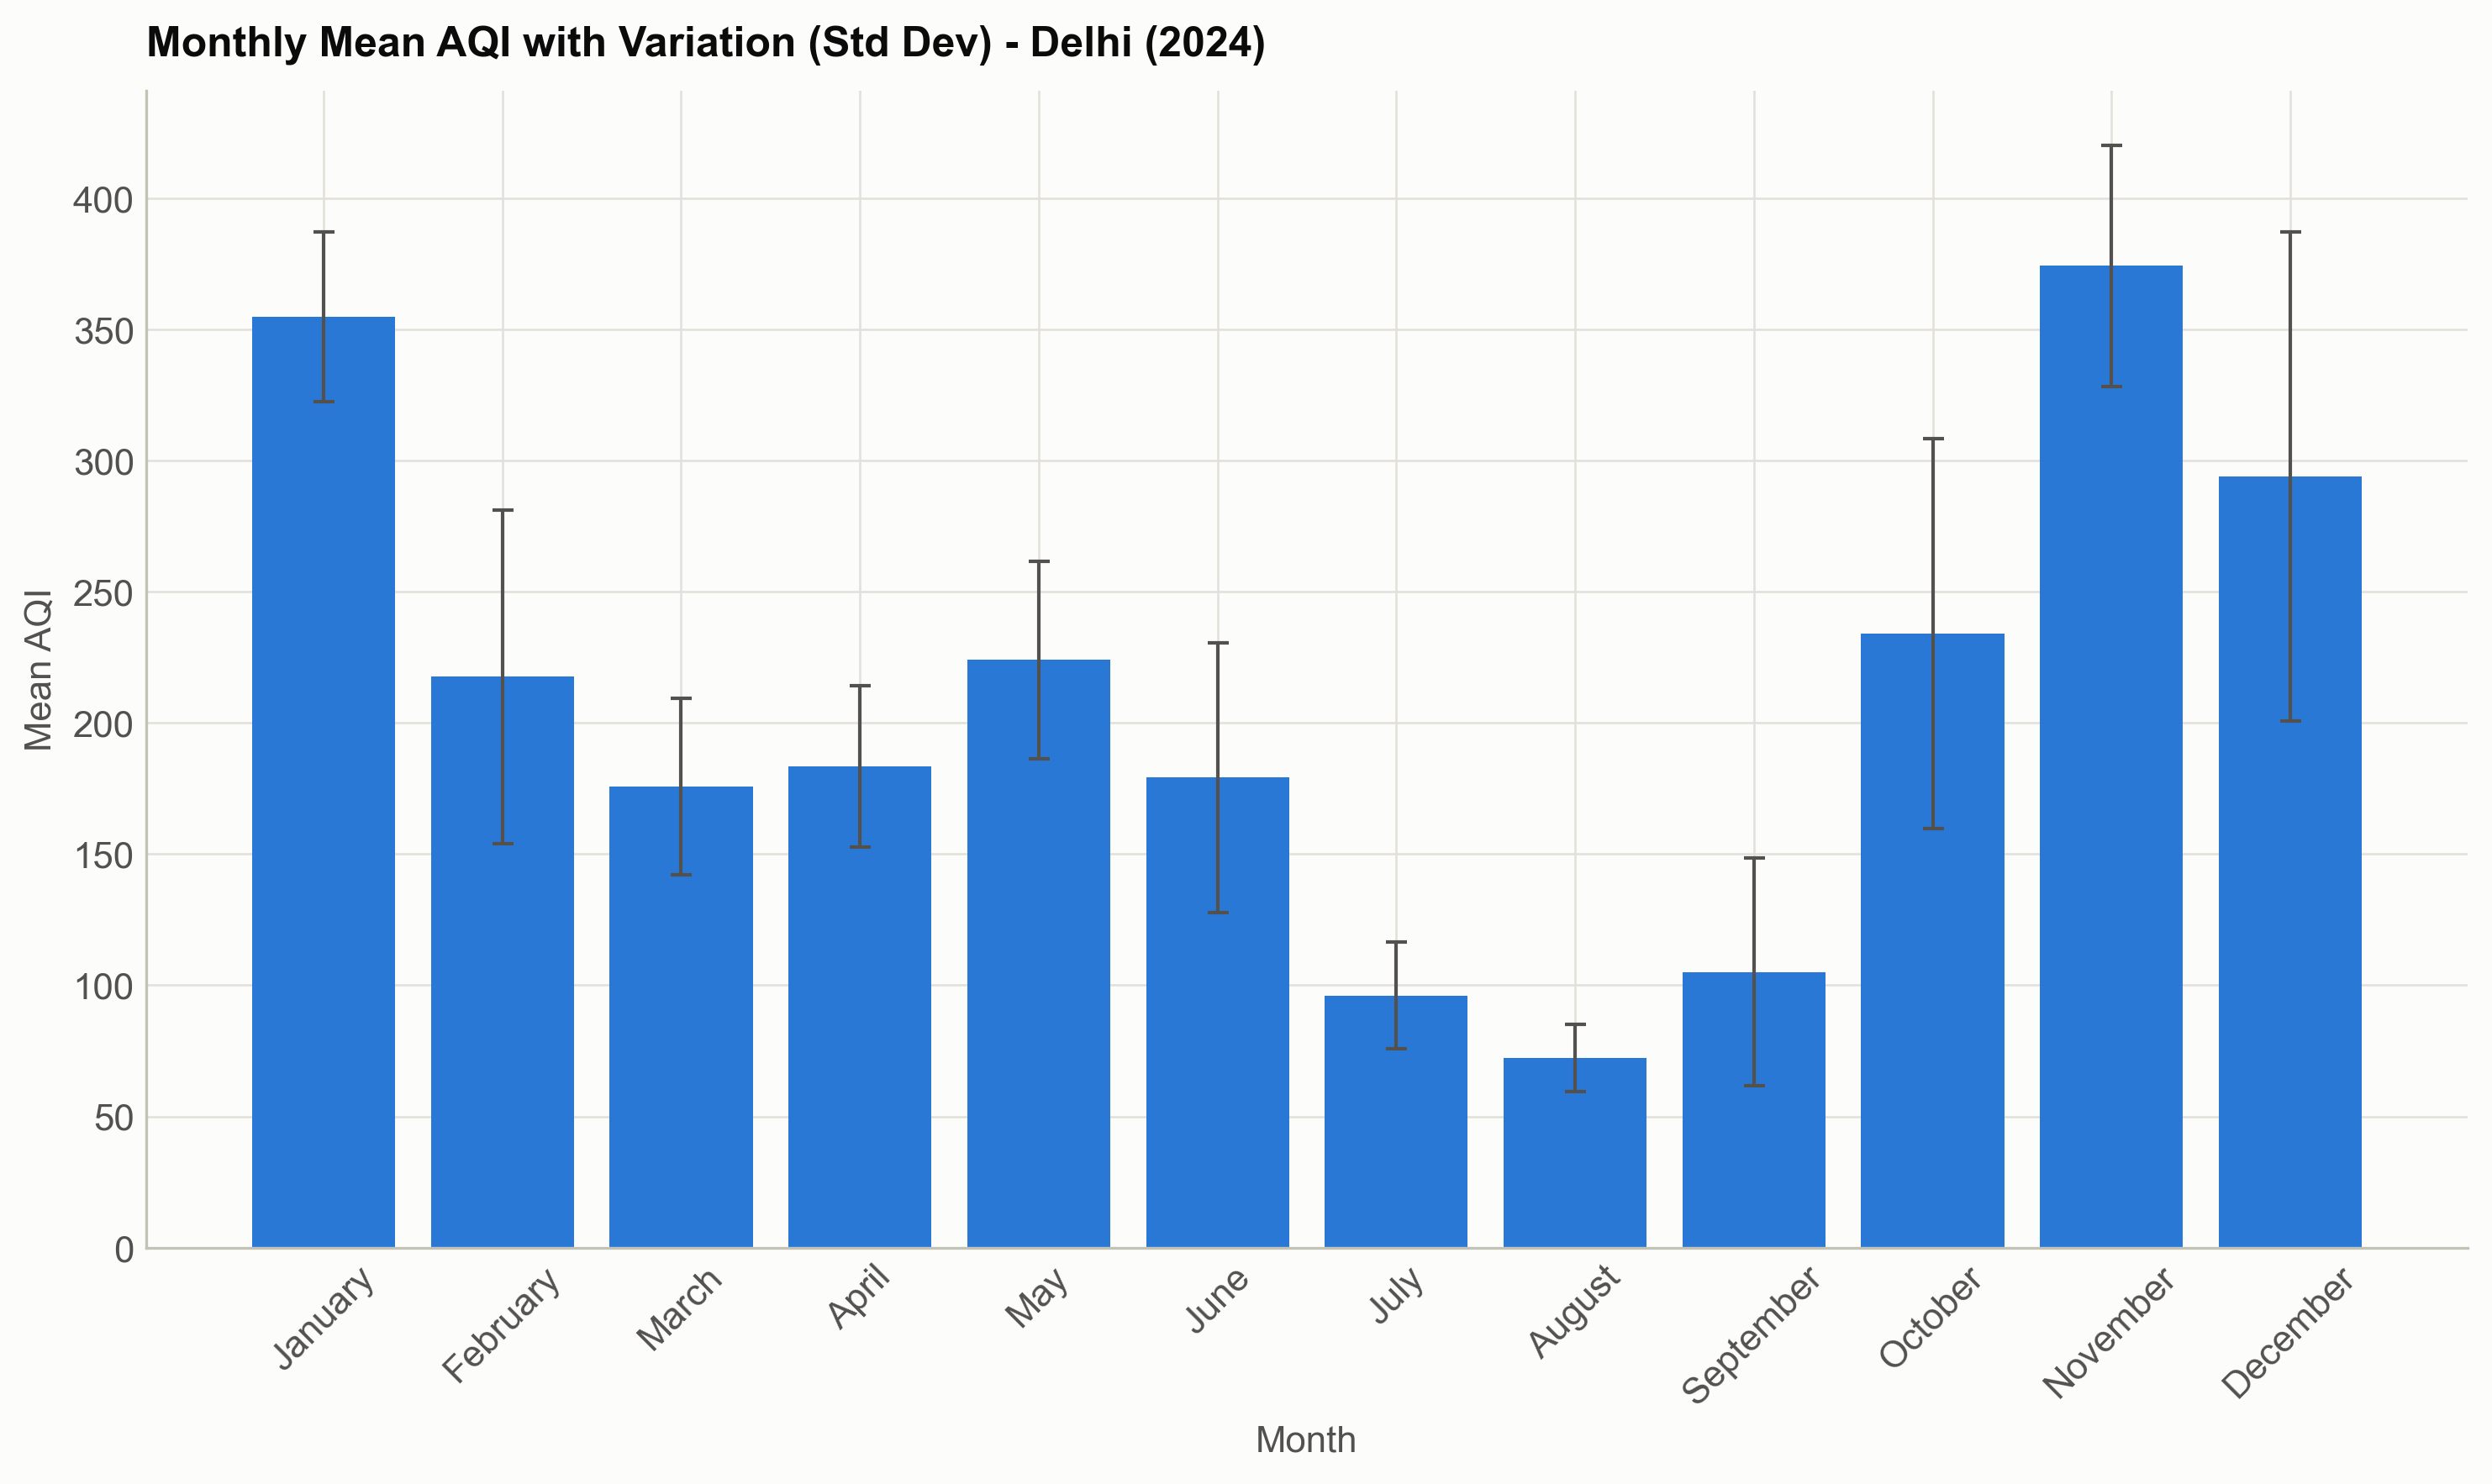

In [6]:
aqi_means = df[months].mean()
aqi_stds = df[months].std()

# The error bars are one standard deviation
plt.figure(figsize=(10, 6))
plt.bar(
    months,
    aqi_means,
    yerr=aqi_stds,
    capsize=3,
    color=PALETTE[0],
    error_kw={"ecolor": INK_2, "elinewidth": 1},
)
plt.ylabel("Mean AQI")
plt.xlabel("Month")
plt.title(f"Monthly Mean AQI with Variation (Std Dev) - {city} ({year})")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()